# Group 4 Exploratory Data Analysis- AP Course Enrollment

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

In [23]:
advanced_placement = pd.read_csv('Advanced Placement.csv')
copy = advanced_placement

/tmp/ipykernel_988/3120422391.py:1: DtypeWarning: Columns (2,6) have mixed types. Specify dtype option on import or set low_memory=False.
  advanced_placement = pd.read_csv('Advanced Placement.csv')


In [24]:
#filter out schools without ap courses
ap_enrolled_schools = advanced_placement[advanced_placement["SCH_APENR_IND"] == "Yes"]

In [25]:
ap_enrolled_schools = ap_enrolled_schools.drop(columns=['LEA_STATE_NAME','LEAID','SCHID', "SCH_JUST", "SCH_APENR_IND"])

In [26]:
ap_enrolled_schools = ap_enrolled_schools.drop(columns=ap_enrolled_schools.columns[39:]) #only looking at overall ap course enrollmemnt, don't need course specific data

In [27]:
ap_enrolled_schools["SCH_NAME"] = ap_enrolled_schools["SCH_NAME"].str.title()

In [28]:
ap_enrolled_schools["LEA_NAME"] = ap_enrolled_schools["LEA_NAME"].str.title()

In [29]:
ap_enrolled_schools.columns = ap_enrolled_schools.columns.str.replace("SCH_AP", "")

In [30]:
#rename columns
ap_enrolled_schools.columns = ap_enrolled_schools.columns.str.replace("ENR_", "")

In [31]:
ap_enrolled_schools = ap_enrolled_schools.replace(-9, np.nan)
ap_enrolled_schools = ap_enrolled_schools.replace(-10, np.nan)

In [33]:
#add non white columns
males_nonwhite = [col for col in ap_enrolled_schools.columns if col.endswith("_M") and col != "ENR_WH_M"]
ap_enrolled_schools["Non-White Male Students"] = ap_enrolled_schools[males_nonwhite].sum(axis=1)

females_nonwhite = [col for col in ap_enrolled_schools.columns if col.endswith("_F") and col != "ENR_WH_F"]
ap_enrolled_schools["Non-White Female Students"] = ap_enrolled_schools[females_nonwhite].sum(axis=1)

nonb_nonwhite = [col for col in ap_enrolled_schools.columns if col.endswith("_X") and col != "ENR_WH_X"]
ap_enrolled_schools["Non-White Nonbinary Students"] = ap_enrolled_schools[nonb_nonwhite].sum(axis=1)

In [34]:
#renaming columns
ap_enrolled_schools = ap_enrolled_schools.rename(columns={"LEA_STATE": "State"})
ap_enrolled_schools = ap_enrolled_schools.rename(columns={"LEA_NAME": "District"})
ap_enrolled_schools = ap_enrolled_schools.rename(columns={"SCH_NAME": "School"})
ap_enrolled_schools = ap_enrolled_schools.rename(columns={"HI_M": "Hispanic Male",
                          "HI_F": "Hispanic Female",
                            "HI_X": "Hispanic Nonbinary"})
ap_enrolled_schools = ap_enrolled_schools.rename(columns={"AM_M": "Native American Male",
                          "AM_F": "Native American Female",
                            "AM_X": "Native American Nonbinary"})
ap_enrolled_schools = ap_enrolled_schools.rename(columns={"AS_M": "Asian Male",
                          "AS_F": "Asian Female",
                            "AS_X": "Asian Nonbinary"})
ap_enrolled_schools = ap_enrolled_schools.rename(columns={"HP_M": "Pacific Islander Male",
                          "HP_F": "Pacific Islander Female",
                            "HP_X": "Pacific Islander Nonbinary"})
ap_enrolled_schools = ap_enrolled_schools.rename(columns={"BL_M": "Black Male",
                          "BL_F": "Black Female",
                            "BL_X": "Black Nonbinary"})
ap_enrolled_schools = ap_enrolled_schools.rename(columns={"WH_M": "White Male",
                          "WH_F": "White Female",
                            "WH_X": "WHite Nonbinary"})
ap_enrolled_schools = ap_enrolled_schools.rename(columns={"TR_M": "Two or more races Male",
                          "TR_F": "Two or more races Female",
                            "TR_X": "Two or more races Nonbinary"})
ap_enrolled_schools = ap_enrolled_schools.rename(columns={"EL_M": "EL Male",
                          "EL_F": "EL Female",
                            "EL_X": "EL Nonbinary"})
ap_enrolled_schools = ap_enrolled_schools.rename(columns={"IDEA_M": "IDEA Male",
                          "IDEA_F": "IDEA Female",
                            "IDEA_X": "IDEA Nonbinary"})
ap_enrolled_schools = ap_enrolled_schools.rename(columns={"504_M": "504 Male", "504_F": "504 Female", "504_X": "504 Nonbinary"})
ap_enrolled_schools = ap_enrolled_schools.rename(columns={"COMBOKEY": "Combokey"})
ap_enrolled_schools = ap_enrolled_schools.rename(columns={"COURSES": "Number of AP Courses Offered"})
ap_enrolled_schools = ap_enrolled_schools.rename(columns={"SEL": "Self selection of AP Courses?"})
ap_enrolled_schools = ap_enrolled_schools.rename(columns={"TOT_APM": "Total Males", "TOT_APF": "Total Females", "TOT_APX": "Total Nonbinary students"})

In [35]:
#adding total columns
ap_enrolled_schools["Total White"] = (
    ap_enrolled_schools["White Male"].fillna(0)
    + ap_enrolled_schools["White Female"].fillna(0)
    + ap_enrolled_schools["WHite Nonbinary"].fillna(0)
)

ap_enrolled_schools["Total Non-White"] = (
    ap_enrolled_schools["Non-White Male Students"].fillna(0)
    + ap_enrolled_schools["Non-White Female Students"].fillna(0)
    + ap_enrolled_schools["Non-White Nonbinary Students"].fillna(0)
)

ap_enrolled_schools["Total EL"] = (
    ap_enrolled_schools["EL Male"].fillna(0)
    + ap_enrolled_schools["EL Female"].fillna(0)
    + ap_enrolled_schools["EL Nonbinary"].fillna(0)
)

ap_enrolled_schools["Total Disability"] = (
    ap_enrolled_schools["IDEA Male"].fillna(0)
    + ap_enrolled_schools["IDEA Female"].fillna(0)
    + ap_enrolled_schools["IDEA Nonbinary"].fillna(0)
    + ap_enrolled_schools["504 Male"].fillna(0)
    + ap_enrolled_schools["504 Female"].fillna(0)
    + ap_enrolled_schools["504 Nonbinary"].fillna(0)
)

ap_enrolled_schools["Total"] = (
    ap_enrolled_schools["Total White"]
    + ap_enrolled_schools["Total Non-White"]
)

In [36]:
ap_enrolled_schools

,State,District,School,Combokey,Number of AP Courses Offered,Self selection of AP Courses?,Hispanic Male,Hispanic Female,Hispanic Nonbinary,Native American Male,...,504 Female,504 Nonbinary,Non-White Male Students,Non-White Female Students,Non-White Nonbinary Students,Total White,Total Non-White,Total EL,Total Disability,Total
4,AL,Albertville City,Albertville High Sch,10000500871,15,No,45,62,NaN,0,...,0,NaN,108,134,0.0,106.0,242.0,3.0,0.0,348.0
10,AL,Marshall County,Asbury Sch,10000600872,2,Yes,2,5,NaN,0,...,0,NaN,4,10,0.0,7.0,14.0,0.0,0.0,21.0
12,AL,Marshall County,Douglas High Sch,10000600878,5,Yes,11,23,NaN,0,...,0,NaN,49,61,0.0,73.0,110.0,1.0,0.0,183.0
14,AL,Marshall County,Kate D Smith Dar High Sch,10000600883,5,Yes,1,3,NaN,0,...,0,NaN,35,40,0.0,65.0,75.0,0.0,0.0,140.0
17,AL,Marshall County,Brindlee Mt High Sch,10000601585,2,Yes,0,1,NaN,0,...,0,NaN,11,13,0.0,22.0,24.0,0.0,1.0,46.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97074,PR,Puerto Rico Department Of Education,Patria Latorre Ramirez,720003002062,3,No,9,10,NaN,0,...,0,NaN,9,10,0.0,0.0,19.0,0.0,0.0,19.0
97075,PR,Puerto Rico Department Of Education,Asuncion Rodriguez De Sala,720003002064,1,No,36,47,NaN,0,...,0,NaN,38,47,0.0,0.0,85.0,0.0,2.0,85.0
97076,PR,Puerto Rico Department Of Education,Eugenio Guerra Cruz,720003002066,3,No,14,6,NaN,0,...,0,NaN,14,6,0.0,0.0,20.0,0.0,0.0,20.0
97087,PR,Puerto Rico Department Of Education,Juan Quirindongo Morell(Superior),720003002085,3,No,5,14,NaN,0,...,0,NaN,5,14,0.0,0.0,19.0,0.0,0.0,19.0


# California

In [37]:
#california descriptive statistics
california_aps = ap_enrolled_schools[ap_enrolled_schools["State"] == "CA"]
california_aps.describe()

,Number of AP Courses Offered,Hispanic Male,Hispanic Female,Hispanic Nonbinary,Native American Male,Native American Female,Native American Nonbinary,Asian Male,Asian Female,Asian Nonbinary,...,504 Female,504 Nonbinary,Non-White Male Students,Non-White Female Students,Non-White Nonbinary Students,Total White,Total Non-White,Total EL,Total Disability,Total
count,1366.000000,1366.000000,1366.000000,0.0,1366.000000,1366.000000,0.0,1366.000000,1366.000000,0.0,...,1366.000000,0.0,1366.000000,1366.000000,1366.0,1366.000000,1366.000000,1366.000000,1366.000000,1366.000000
mean,11.818448,60.497072,83.442899,NaN,0.381406,0.491947,NaN,36.529283,37.409956,NaN,...,6.292826,NaN,159.918741,193.112006,0.0,75.510249,353.030747,11.819912,18.732064,428.540996
std,7.284334,63.546917,86.333458,NaN,0.971494,1.269366,NaN,78.753961,78.705462,NaN,...,11.316780,NaN,165.404479,184.751023,0.0,124.036156,347.150929,20.516619,26.763185,443.086749
min,1.000000,0.000000,0.000000,NaN,0.000000,0.000000,NaN,0.000000,0.000000,NaN,...,0.000000,NaN,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
25%,6.000000,11.000000,16.000000,NaN,0.000000,0.000000,NaN,0.000000,1.000000,NaN,...,0.000000,NaN,31.000000,42.000000,0.0,3.000000,75.250000,1.000000,2.000000,89.250000
50%,11.000000,43.500000,57.000000,NaN,0.000000,0.000000,NaN,6.000000,6.000000,NaN,...,2.000000,NaN,110.000000,142.000000,0.0,17.000000,257.000000,5.000000,10.000000,297.000000
75%,17.000000,91.750000,127.750000,NaN,0.000000,1.000000,NaN,31.000000,33.000000,NaN,...,7.000000,NaN,237.000000,302.000000,0.0,94.750000,532.000000,15.000000,24.000000,621.250000
max,41.000000,607.000000,647.000000,NaN,12.000000,22.000000,NaN,669.000000,657.000000,NaN,...,118.000000,NaN,1260.000000,1378.000000,0.0,894.000000,2638.000000,357.000000,225.000000,3233.000000


Text(0, 0.5, 'Frequency')

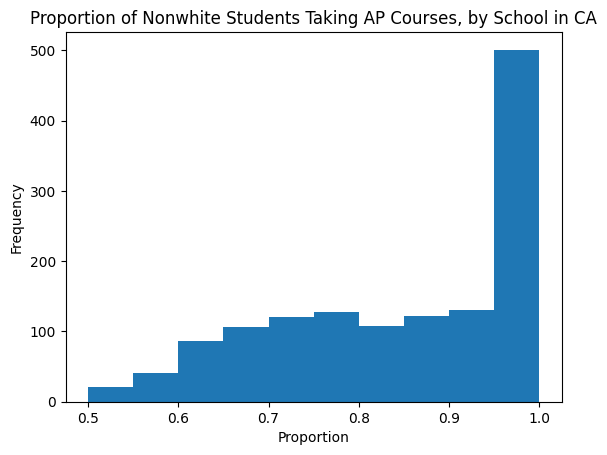

In [39]:
nonwhite_prop_ca = california_aps['Total Non-White']/california_aps['Total']
plt.hist(nonwhite_prop_ca)
plt.title('Proportion of Nonwhite Students Taking AP Courses, by School in CA')
plt.xlabel('Proportion')
plt.ylabel('Frequency')

Alt Text: A histogram displaying the proportions of non-white students per school taking an AP course in California, with an X-axis of the proportion values, y-axis of frequency, and bin size of 0.1. This histogram is right-skewed, meaning that there tends to be higher proportions of non-white students taking AP courses per schools.

Text(0, 0.5, 'Frequency')

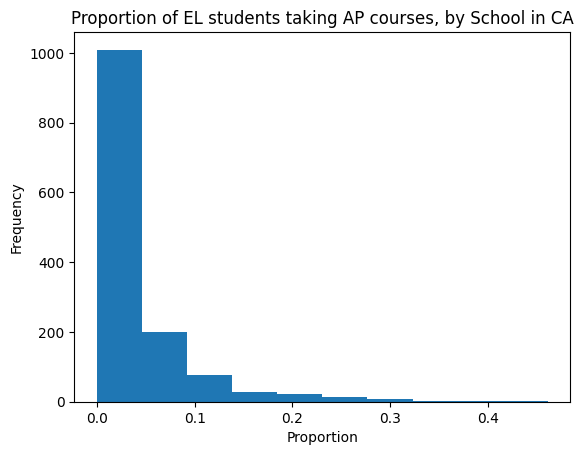

In [43]:
# plotting proportion of EL students taking AP courses
EL_prop_ca = california_aps['Total EL']/california_aps['Total']
plt.hist(EL_prop_ca)
plt.title('Proportion of EL students taking AP courses, by School in CA')
plt.xlabel('Proportion')
plt.ylabel('Frequency')

Alt Text: A histogram displaying the proportions of EL (English Learning) students per school taking AP courses in California, with an X-axis of the proportion values, y-axis of frequency, and bin size of 0.1. This histogram is heavily left-skewed, meaning that there tend to be much lower proportions of EL Students students taking AP courses in schools.


Text(0, 0.5, 'Frequency')

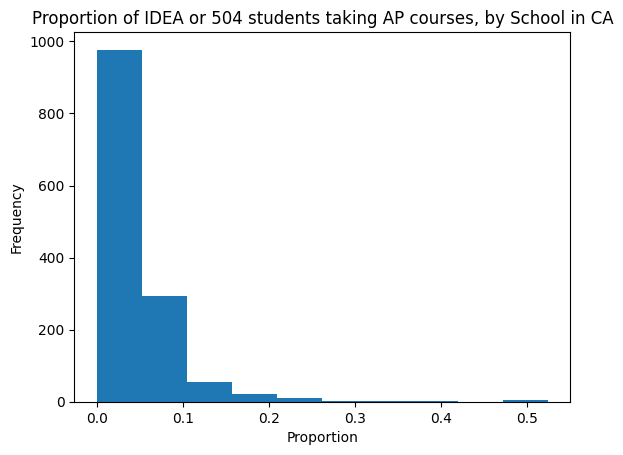

In [44]:
# Plotting the proportion of IDEA and 504 students taking AP courses
IDEA_prop_ca = california_aps['Total Disability']/california_aps['Total']
plt.hist(IDEA_prop_ca)
plt.title('Proportion of IDEA or 504 students taking AP courses, by School in CA')
plt.xlabel('Proportion')
plt.ylabel('Frequency')

Alt Text: A histogram displaying the proportions of IDEA (Individuals with Disabilities) and students with 504 plans per school taking AP courses in California, with an X-axis of the proportion values, y-axis of frequency, and bin size of 0.1. This histogram is heavily left-skewed, demonstrating that there tend to be much lower proportions of IDEA and 504 Students taking AP courses in schools.

# Massachusetts

In [40]:
#massachusetts descriptive statistics
massachusetts_aps = ap_enrolled_schools[ap_enrolled_schools["State"] == "MA"]
massachusetts_aps.describe()

,Number of AP Courses Offered,Hispanic Male,Hispanic Female,Hispanic Nonbinary,Native American Male,Native American Female,Native American Nonbinary,Asian Male,Asian Female,Asian Nonbinary,...,504 Female,504 Nonbinary,Non-White Male Students,Non-White Female Students,Non-White Nonbinary Students,Total White,Total Non-White,Total EL,Total Disability,Total
count,334.000000,334.000000,334.000000,0.0,334.000000,334.000000,0.0,334.000000,334.000000,0.0,...,334.000000,0.0,334.000000,334.000000,334.0,334.000000,334.000000,334.000000,334.000000,334.000000
mean,14.332335,11.925150,15.544910,NaN,0.119760,0.176647,NaN,12.763473,13.200599,NaN,...,8.766467,NaN,100.643713,122.467066,0.0,119.955090,223.110778,2.871257,22.787425,343.065868
std,7.823909,19.301397,24.333076,NaN,0.376524,0.491910,NaN,30.270766,31.394208,NaN,...,9.075225,NaN,92.119171,104.740709,0.0,107.779922,194.882662,6.370320,21.844104,290.399696
min,1.000000,0.000000,0.000000,NaN,0.000000,0.000000,NaN,0.000000,0.000000,NaN,...,0.000000,NaN,0.000000,0.000000,0.0,0.000000,1.000000,0.000000,0.000000,2.000000
25%,8.000000,2.000000,3.000000,NaN,0.000000,0.000000,NaN,1.000000,1.000000,NaN,...,2.000000,NaN,37.000000,46.250000,0.0,30.000000,85.250000,0.000000,7.250000,121.000000
50%,14.000000,5.000000,7.000000,NaN,0.000000,0.000000,NaN,3.000000,3.000000,NaN,...,6.000000,NaN,70.500000,96.000000,0.0,93.000000,166.000000,0.500000,16.000000,264.500000
75%,20.000000,13.000000,17.000000,NaN,0.000000,0.000000,NaN,11.000000,11.000000,NaN,...,13.000000,NaN,139.750000,171.000000,0.0,185.500000,314.750000,3.000000,31.750000,496.750000
max,37.000000,155.000000,184.000000,NaN,2.000000,3.000000,NaN,327.000000,354.000000,NaN,...,54.000000,NaN,644.000000,740.000000,0.0,501.000000,1384.000000,47.000000,142.000000,1805.000000


Text(0, 0.5, 'Frequency')

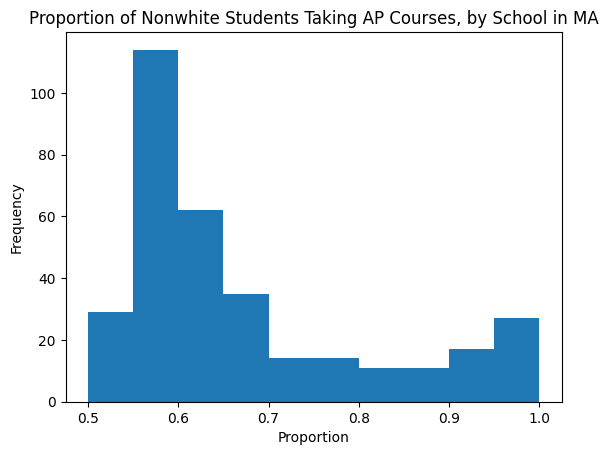

In [45]:
nonwhite_prop_ma = massachusetts_aps['Total Non-White']/massachusetts_aps['Total']
plt.hist(nonwhite_prop_ma)
plt.title('Proportion of Nonwhite Students Taking AP Courses, by School in MA')
plt.xlabel('Proportion')
plt.ylabel('Frequency')

Alt Text: A histogram displaying the proportions of non-white students per school taking AP courses in Massachusetts, with an X-axis of the proportion values, y-axis of frequency, and bin size of 0.1.

Text(0, 0.5, 'Frequency')

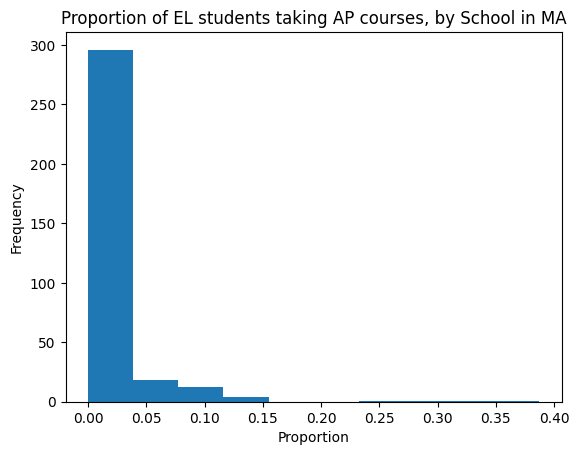

In [46]:
# plotting proportion of EL students taking AP courses
EL_prop_ma = massachusetts_aps['Total EL']/massachusetts_aps['Total']
plt.hist(EL_prop_ma)
plt.title('Proportion of EL students taking AP courses, by School in MA')
plt.xlabel('Proportion')
plt.ylabel('Frequency')

Alt Text: A histogram displaying the proportions of EL (English Learning) students per school taking AP courses in Massachusetts, with an X-axis of the proportion values, y-axis of frequency, and bin size of 0.1.



Text(0, 0.5, 'Frequency')

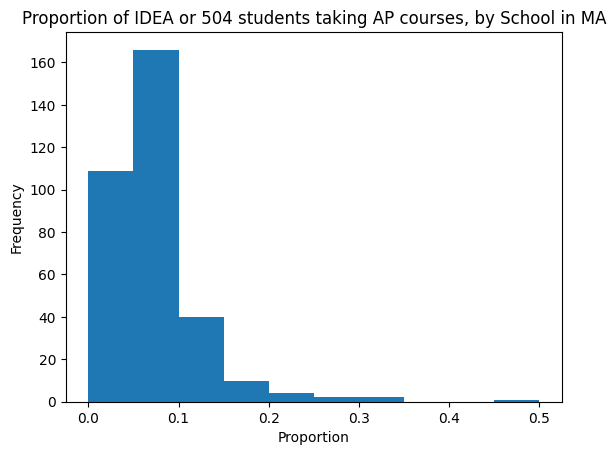

In [47]:
# Plotting the proportion of IDEA and 504 students taking AP courses
IDEA_prop_ma = massachusetts_aps['Total Disability']/massachusetts_aps['Total']
plt.hist(IDEA_prop_ma)
plt.title('Proportion of IDEA or 504 students taking AP courses, by School in MA')
plt.xlabel('Proportion')
plt.ylabel('Frequency')

Alt Text: A histogram displaying the proportions of IDEA (Individuals with Disabilities) and students with a 504 plan per school taking AP courses in Massachusetts, with an X-axis of the proportion values, y-axis of frequency, and bin size of 0.1.

# Texas

In [48]:
#texas descriptive statistics
texas_aps = ap_enrolled_schools[ap_enrolled_schools["State"] == "TX"]
texas_aps.describe()

,Number of AP Courses Offered,Hispanic Male,Hispanic Female,Hispanic Nonbinary,Native American Male,Native American Female,Native American Nonbinary,Asian Male,Asian Female,Asian Nonbinary,...,504 Female,504 Nonbinary,Non-White Male Students,Non-White Female Students,Non-White Nonbinary Students,Total White,Total Non-White,Total EL,Total Disability,Total
count,1221.000000,1221.000000,1221.000000,0.0,1221.000000,1221.000000,0.0,1221.000000,1221.000000,0.0,...,1221.000000,0.0,1221.000000,1221.000000,1221.0,1221.000000,1221.000000,1221.000000,1221.000000,1221.000000
mean,12.285831,76.134316,92.047502,NaN,0.448812,0.454545,NaN,21.298116,21.282555,NaN,...,14.393120,NaN,201.715807,230.013923,0.0,92.343980,431.729730,50.348075,34.990172,524.073710
std,8.994864,82.722913,99.513024,NaN,1.144499,1.021381,NaN,66.672822,66.004182,NaN,...,21.369645,NaN,208.991333,228.730120,0.0,153.996321,433.787748,73.980254,45.278970,552.633609
min,1.000000,0.000000,0.000000,NaN,0.000000,0.000000,NaN,0.000000,0.000000,NaN,...,0.000000,NaN,0.000000,0.000000,0.0,0.000000,1.000000,0.000000,0.000000,1.000000
25%,4.000000,9.000000,13.000000,NaN,0.000000,0.000000,NaN,0.000000,0.000000,NaN,...,1.000000,NaN,32.000000,43.000000,0.0,4.000000,78.000000,2.000000,4.000000,102.000000
50%,11.000000,48.000000,63.000000,NaN,0.000000,0.000000,NaN,1.000000,1.000000,NaN,...,6.000000,NaN,134.000000,158.000000,0.0,22.000000,298.000000,21.000000,20.000000,344.000000
75%,19.000000,118.000000,139.000000,NaN,1.000000,1.000000,NaN,9.000000,9.000000,NaN,...,18.000000,NaN,313.000000,364.000000,0.0,99.000000,674.000000,66.000000,46.000000,768.000000
max,37.000000,432.000000,584.000000,NaN,23.000000,17.000000,NaN,975.000000,1013.000000,NaN,...,185.000000,NaN,1497.000000,1496.000000,0.0,1063.000000,2993.000000,533.000000,377.000000,3393.000000


Text(0, 0.5, 'Frequency')

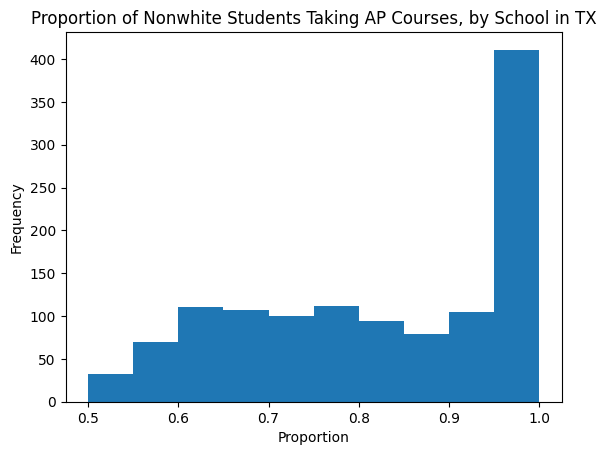

In [49]:
nonwhite_prop_tx = texas_aps['Total Non-White']/texas_aps['Total']
plt.hist(nonwhite_prop_tx)
plt.title('Proportion of Nonwhite Students Taking AP Courses, by School in TX')
plt.xlabel('Proportion')
plt.ylabel('Frequency')

Alt Text: A histogram displaying the proportions of non-white students per school taking AP courses in Texas, with an X-axis of the proportion values, y-axis of frequency, and bin size of 0.1.



Text(0, 0.5, 'Frequency')

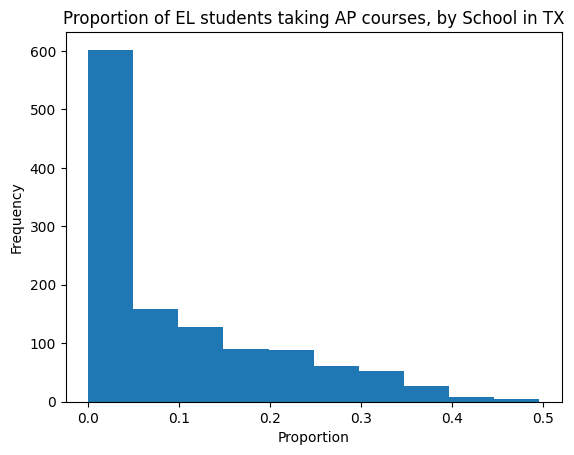

In [50]:
# plotting proportion of EL students taking AP courses
EL_prop_tx = texas_aps['Total EL']/texas_aps['Total']
plt.hist(EL_prop_tx)
plt.title('Proportion of EL students taking AP courses, by School in TX')
plt.xlabel('Proportion')
plt.ylabel('Frequency')

Alt Text: A histogram displaying the proportions of EL (English Learning) students per school taking AP courses in Texas, with an X-axis of the proportion values, y-axis of frequency, and bin size of 0.1.



Text(0, 0.5, 'Frequency')

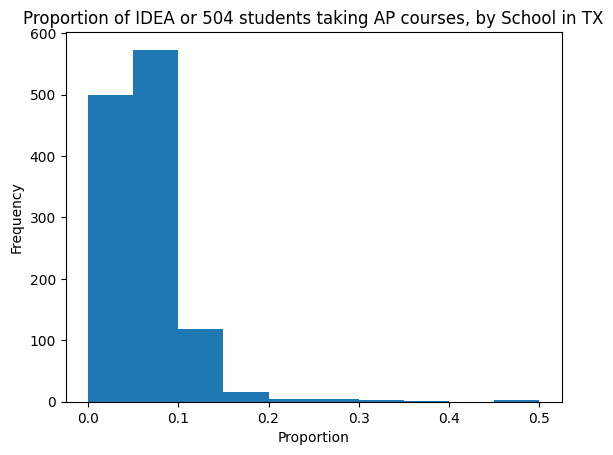

In [52]:
# Plotting the proportion of IDEA and 504 students taking AP courses
IDEA_prop_tx = texas_aps['Total Disability']/texas_aps['Total']
plt.hist(IDEA_prop_tx)
plt.title('Proportion of IDEA or 504 students taking AP courses, by School in TX')
plt.xlabel('Proportion')
plt.ylabel('Frequency')

Alt Text: A histogram displaying the proportions of IDEA (Individuals with Disabilities) and students with a 504 plan per school taking AP courses in Texas, with an X-axis of the proportion values, y-axis of frequency, and bin size of 0.1.

# New Mexico

In [54]:
#new mexico descriptive statistics
new_mexico_aps = ap_enrolled_schools[ap_enrolled_schools["State"] == "NM"]
new_mexico_aps.describe()

,Number of AP Courses Offered,Hispanic Male,Hispanic Female,Hispanic Nonbinary,Native American Male,Native American Female,Native American Nonbinary,Asian Male,Asian Female,Asian Nonbinary,...,504 Female,504 Nonbinary,Non-White Male Students,Non-White Female Students,Non-White Nonbinary Students,Total White,Total Non-White,Total EL,Total Disability,Total
count,92.000000,92.000000,92.000000,0.0,92.000000,92.000000,0.0,92.000000,92.000000,0.0,...,92.000000,0.0,92.000000,92.000000,92.0,92.000000,92.000000,92.000000,92.000000,92.000000
mean,9.673913,46.521739,59.782609,NaN,4.565217,6.880435,NaN,2.597826,2.554348,NaN,...,2.913043,NaN,96.597826,120.108696,0.0,45.043478,216.706522,29.130435,11.663043,261.750000
std,8.354914,55.266881,69.131476,NaN,10.478974,15.611944,NaN,6.350668,6.255308,NaN,...,5.420053,NaN,104.637633,125.048338,0.0,58.718347,228.544729,50.613428,14.669455,273.186875
min,1.000000,0.000000,0.000000,NaN,0.000000,0.000000,NaN,0.000000,0.000000,NaN,...,0.000000,NaN,0.000000,0.000000,0.0,0.000000,1.000000,0.000000,0.000000,1.000000
25%,3.000000,4.000000,3.000000,NaN,0.000000,0.000000,NaN,0.000000,0.000000,NaN,...,0.000000,NaN,14.250000,22.000000,0.0,6.000000,34.750000,0.000000,1.000000,52.000000
50%,7.000000,25.000000,28.000000,NaN,0.000000,1.000000,NaN,0.000000,0.500000,NaN,...,0.000000,NaN,53.500000,61.000000,0.0,18.500000,120.500000,8.500000,5.000000,147.500000
75%,15.000000,69.000000,91.250000,NaN,4.000000,6.000000,NaN,3.000000,2.250000,NaN,...,3.250000,NaN,164.250000,198.500000,0.0,62.750000,356.750000,36.250000,18.000000,447.250000
max,36.000000,245.000000,273.000000,NaN,62.000000,98.000000,NaN,54.000000,53.000000,NaN,...,33.000000,NaN,443.000000,476.000000,0.0,281.000000,919.000000,310.000000,66.000000,1106.000000


Text(0, 0.5, 'Frequency')

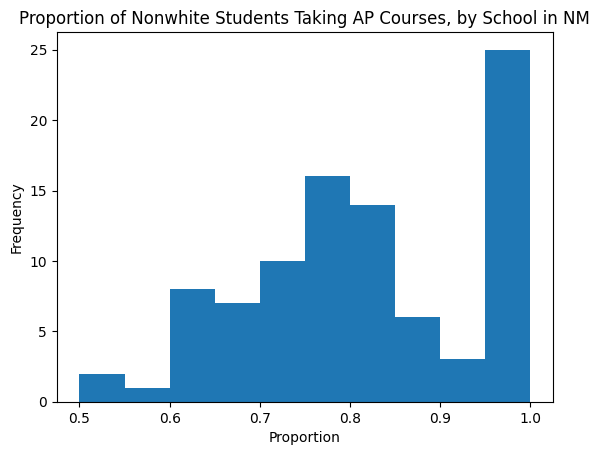

In [55]:
nonwhite_prop_nm = new_mexico_aps['Total Non-White']/new_mexico_aps['Total']
plt.hist(nonwhite_prop_nm)
plt.title('Proportion of Nonwhite Students Taking AP Courses, by School in NM')
plt.xlabel('Proportion')
plt.ylabel('Frequency')

Alt Text: A histogram displaying the proportions of non-white students per school taking AP courses in New Mexico, with an X-axis of the proportion values, y-axis of frequency, and bin size of 0.1.




Text(0, 0.5, 'Frequency')

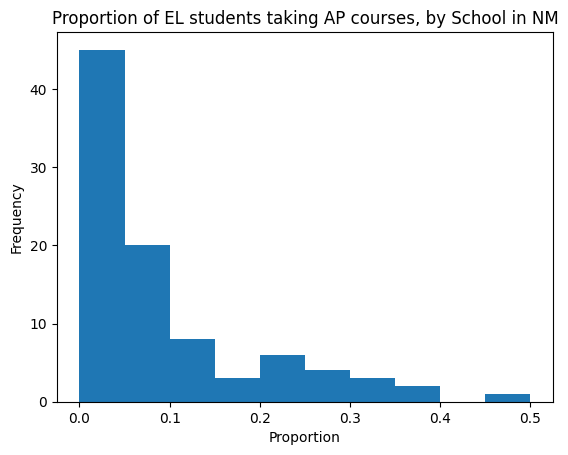

In [56]:
# plotting proportion of EL students taking AP courses
EL_prop_nm = new_mexico_aps['Total EL']/new_mexico_aps['Total']
plt.hist(EL_prop_nm)
plt.title('Proportion of EL students taking AP courses, by School in NM')
plt.xlabel('Proportion')
plt.ylabel('Frequency')

Alt Text: A histogram displaying the proportions of EL (English Learning) students per school taking AP courses in New Mexico, with an X-axis of the proportion values, y-axis of frequency, and bin size of 0.1.



Text(0, 0.5, 'Frequency')

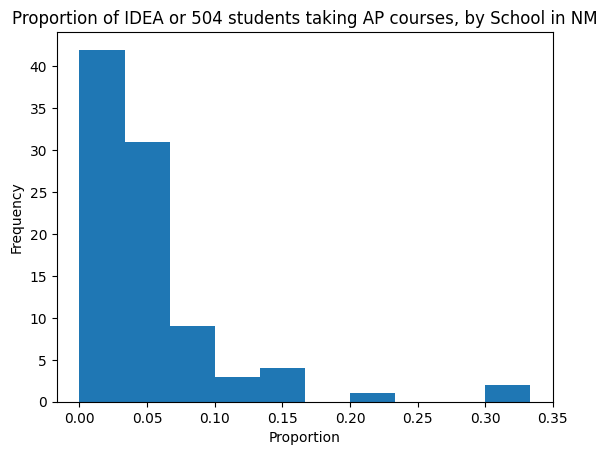

In [57]:
# Plotting the proportion of IDEA and 504 students taking AP courses
IDEA_prop_nm = new_mexico_aps['Total Disability']/new_mexico_aps['Total']
plt.hist(IDEA_prop_nm)
plt.title('Proportion of IDEA or 504 students taking AP courses, by School in NM')
plt.xlabel('Proportion')
plt.ylabel('Frequency')

Alt Text: A histogram displaying the proportions of IDEA (Individuals with Disabilities) and students with a 504 plan per school taking AP courses in New Mexico, with an X-axis of the proportion values, y-axis of frequency, and bin size of 0.1.
